In [35]:
# import
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score


In [8]:
# Load the dataset
data = pd.read_csv("bank-additional-full.csv", sep=";")

print("Rows:", data.shape[0])
print("Input variables:", data.shape[1] - 1)

data.head()

Rows: 41188
Input variables: 20


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [11]:
# The first 80% for training and validation
split_row = int(len(data) * 0.8)
train_val = data.iloc[:split_row].copy()

# The last 20% for final testing
test = data.iloc[split_row:].copy()

# Divide the first 80% into five consecutive blocks
block_size = len(train_val) // 5
blocks = []

for i in range(5):
    start = i * block_size
    end = start + block_size
    blocks.append(train_val.iloc[start:end].copy())

# Check the number of rows
print("Training and validation rows:", len(train_val))
print("Test rows:", len(test))

for i in range(5):
    print(f"Block {i + 1}: {len(blocks[i])} rows")

Training and validation rows: 32950
Test rows: 8238
Block 1: 6590 rows
Block 2: 6590 rows
Block 3: 6590 rows
Block 4: 6590 rows
Block 5: 6590 rows


 Block  Subscription rate (%)
     1                   2.90
     2                   4.39
     3                   6.34
     4                   5.52
     5                  12.72


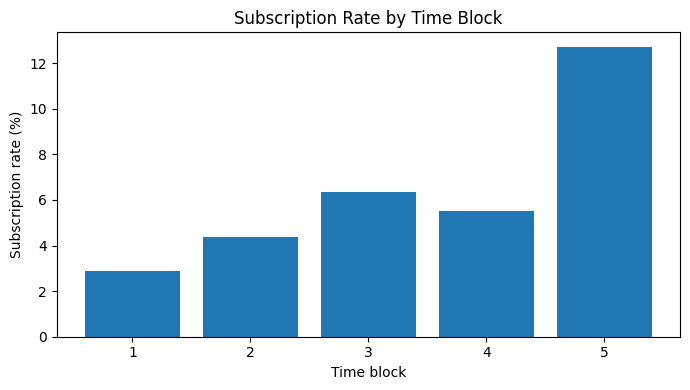

In [18]:
# Calculate the subscription percentage in each block
rates = []

for block in blocks:
    rate = (block["y"] == "yes").mean() * 100
    rates.append(rate)

# Show the results for the five blocks
block_rates = pd.DataFrame({
    "Block": range(1, 6),
    "Subscription rate (%)": rates
})

print(block_rates.round(2).to_string(index=False))

# Plot the rates in their original time order
plt.figure(figsize=(7, 4))
plt.bar(block_rates["Block"], block_rates["Subscription rate (%)"])

plt.xlabel("Time block")
plt.ylabel("Subscription rate (%)")
plt.title("Subscription Rate by Time Block")
plt.xticks(range(1, 6))
plt.tight_layout()

# Save and show the figure 
plt.savefig("subscription_rate.png", dpi=300)
plt.show()

According to the UCI description, the rows are in date order from May 2008 to November 2010. We kept the original row order. The subscription rate changes across the five blocks and is highest in block 5, so we use time-ordered validation.

In [26]:
# Build four forward validation folds
folds = []

for k in range(1, 5):
    # Combine the earlier blocks for training
    train_data = pd.concat(blocks[:k])

    # Use the next block for validation
    valid_data = blocks[k].copy()

    # Save the training and validation pair
    folds.append((train_data, valid_data))

    print(
        f"Fold {k}: training = {len(train_data)}, "
        f"validation = {len(valid_data)}"
    )

Fold 1: training = 6590, validation = 6590
Fold 2: training = 13180, validation = 6590
Fold 3: training = 19770, validation = 6590
Fold 4: training = 26360, validation = 6590


In [ ]:
# Set A 
# Set A features
num_a = ["age"]
cat_a = ["job", "marital", "education", "default", "housing", "loan"]
features_a = num_a + cat_a

# Scale numbers and encode categories
preprocess_a = ColumnTransformer([
    ("num", StandardScaler(), num_a),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_a)
])

print("Number of A features:", len(features_a))

Number of A features: 7


In [62]:
# Values to try
#c_values = np.logspace(-4, 4, 9)

# Try smaller C values
c_values = np.logspace(-8, 4, 13)
results_a = []

for c in c_values:
    fold_scores = []

    for train_data, valid_data in folds:
        # Select inputs and labels
        X_train = train_data[features_a]
        y_train = (train_data["y"] == "yes").astype(int)

        X_valid = valid_data[features_a]
        y_valid = (valid_data["y"] == "yes").astype(int)

        # Preprocessing and L2 logistic regression
        model = Pipeline([
            ("preprocess", clone(preprocess_a)),
            ("logistic", LogisticRegression(
                C=c,
                solver="lbfgs",
                max_iter=5000,
                random_state=42
            ))
        ])

        # Train and predict probabilities
        model.fit(X_train, y_train)
        probabilities = model.predict_proba(X_valid)[:, 1]

        # Calculate validation AP
        ap = average_precision_score(y_valid, probabilities)
        fold_scores.append(ap)

    # Save results for this C
    results_a.append({
        "C": c,
        "Mean AP": np.mean(fold_scores),
        "Fold SD": np.std(fold_scores, ddof=1),
        "Fold AP": fold_scores
    })

results_a = pd.DataFrame(results_a)

# Choose the highest mean AP
best_a = results_a.loc[results_a["Mean AP"].idxmax()]

print(results_a[["C", "Mean AP", "Fold SD"]].to_string(index=False))
print("\nBest C:", best_a["C"])
print("Mean validation AP:", best_a["Mean AP"])
print("Fold AP:", best_a["Fold AP"])

           C  Mean AP  Fold SD
1.000000e-08 0.092189 0.066722
1.000000e-07 0.092170 0.066893
1.000000e-06 0.092063 0.066798
1.000000e-05 0.092111 0.066722
1.000000e-04 0.091734 0.066827
1.000000e-03 0.090642 0.065392
1.000000e-02 0.085675 0.057746
1.000000e-01 0.082907 0.053217
1.000000e+00 0.083731 0.051997
1.000000e+01 0.083869 0.051905
1.000000e+02 0.083801 0.051956
1.000000e+03 0.083805 0.051960
1.000000e+04 0.083806 0.051959

Best C: 1e-08
Mean validation AP: 0.09218946898636672
Fold AP: [np.float64(0.04521124469498285), np.float64(0.06939329509121228), np.float64(0.06306587391329746), np.float64(0.19108746224597428)]


In [43]:
# Set B: Set A plus history variables
# history variables
folds_b = []

for train_data, valid_data in folds:
    train_b = train_data.copy()
    valid_b = valid_data.copy()

    for part in [train_b, valid_b]:
        part["never_contacted"] = (part["pdays"] == 999).astype(int)
        part.loc[part["never_contacted"] == 1, "pdays"] = 0

    folds_b.append((train_b, valid_b))

# Set B features
num_b = num_a + ["pdays", "previous"]
cat_b = cat_a + ["poutcome"]
features_b = num_b + cat_b + ["never_contacted"]

# Set B preprocessing
preprocess_b = ColumnTransformer([
    ("num", StandardScaler(), num_b),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_b),
    ("flag", "passthrough", ["never_contacted"])
])

print("B inputs before encoding:", len(features_b))

B inputs before encoding: 11


In [63]:
# Values to try
#c_values = np.logspace(-8, 4, 13)

results_b = []

for c in c_values:
    fold_scores = []

    for train_data, valid_data in folds_b:
        # Select inputs and labels
        X_train = train_data[features_b]
        y_train = (train_data["y"] == "yes").astype(int)

        X_valid = valid_data[features_b]
        y_valid = (valid_data["y"] == "yes").astype(int)

        # Build the model
        model = Pipeline([
            ("preprocess", clone(preprocess_b)),
            ("logistic", LogisticRegression(
                C=c,
                solver="lbfgs",
                max_iter=5000,
                random_state=42
            ))
        ])

        # Train and predict
        model.fit(X_train, y_train)
        probabilities = model.predict_proba(X_valid)[:, 1]

        # Calculate AP
        ap = average_precision_score(y_valid, probabilities)
        fold_scores.append(ap)

    # Save results
    results_b.append({
        "C": c,
        "Mean AP": np.mean(fold_scores),
        "Fold SD": np.std(fold_scores, ddof=1),
        "Fold AP": fold_scores
    })

results_b = pd.DataFrame(results_b)

# Choose the highest mean AP
best_b = results_b.loc[results_b["Mean AP"].idxmax()]

print(results_b[["C", "Mean AP", "Fold SD"]].to_string(index=False))
print("\nBest C:", best_b["C"])
print("Mean validation AP:", best_b["Mean AP"])
print("Fold AP:", best_b["Fold AP"])

           C  Mean AP  Fold SD
1.000000e-08 0.101582 0.085641
1.000000e-07 0.101565 0.085815
1.000000e-06 0.101558 0.085667
1.000000e-05 0.101460 0.085710
1.000000e-04 0.101342 0.085745
1.000000e-03 0.100197 0.084299
1.000000e-02 0.094855 0.076183
1.000000e-01 0.091895 0.070172
1.000000e+00 0.093535 0.075264
1.000000e+01 0.093592 0.075412
1.000000e+02 0.093588 0.075385
1.000000e+03 0.093574 0.075395
1.000000e+04 0.093575 0.075392

Best C: 1e-08
Mean validation AP: 0.10158181453555049
Fold AP: [np.float64(0.045158006409359956), np.float64(0.06942287419435107), np.float64(0.06262116703653843), np.float64(0.22912521050195253)]


In [52]:
# Set C: Set B plus economic indicators
# Set C features
econ_features = [
    "emp.var.rate",
    "cons.price.idx",
    "cons.conf.idx",
    "euribor3m",
    "nr.employed"
]

num_c = num_b + econ_features
cat_c = cat_b.copy()
features_c = num_c + cat_c + ["never_contacted"]

# Set C preprocessing
preprocess_c = ColumnTransformer([
    ("num", StandardScaler(), num_c),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_c),
    ("flag", "passthrough", ["never_contacted"])
])

print("C inputs before encoding:", len(features_c))

C inputs before encoding: 16


In [55]:
results_c = []

for c in c_values:
    fold_scores = []

    for train_data, valid_data in folds_b:
        # Select inputs and labels
        X_train = train_data[features_c]
        y_train = (train_data["y"] == "yes").astype(int)

        X_valid = valid_data[features_c]
        y_valid = (valid_data["y"] == "yes").astype(int)

        # Build the model
        model = Pipeline([
            ("preprocess", clone(preprocess_c)),
            ("logistic", LogisticRegression(
                C=c,
                solver="lbfgs",
                max_iter=5000,
                random_state=42
            ))
        ])

        # Train and predict
        model.fit(X_train, y_train)
        probabilities = model.predict_proba(X_valid)[:, 1]

        # Calculate AP
        ap = average_precision_score(y_valid, probabilities)
        fold_scores.append(ap)

    # Save results
    results_c.append({
        "C": c,
        "Mean AP": np.mean(fold_scores),
        "Fold SD": np.std(fold_scores, ddof=1),
        "Fold AP": fold_scores
    })

results_c = pd.DataFrame(results_c)

# Choose the highest mean AP
best_c = results_c.loc[results_c["Mean AP"].idxmax()]

print(results_c[["C", "Mean AP", "Fold SD"]].to_string(index=False))
print("\nBest C:", best_c["C"])
print("Mean validation AP:", best_c["Mean AP"])
print("Fold AP:", best_c["Fold AP"])

           C  Mean AP  Fold SD
1.000000e-08 0.078498 0.049276
1.000000e-07 0.078512 0.049274
1.000000e-06 0.078548 0.049268
1.000000e-05 0.078768 0.049803
1.000000e-04 0.078483 0.049279
1.000000e-03 0.077685 0.047923
1.000000e-02 0.073526 0.040202
1.000000e-01 0.072386 0.040280
1.000000e+00 0.073216 0.040624
1.000000e+01 0.073175 0.040589
1.000000e+02 0.073235 0.040557
1.000000e+03 0.073235 0.040557
1.000000e+04 0.073232 0.040552

Best C: 1e-05
Mean validation AP: 0.07876752553088018
Fold AP: [np.float64(0.042738061851380835), np.float64(0.0666723523057239), np.float64(0.05364375506709058), np.float64(0.15201593289932544)]


In [65]:
# Collect the three results
summary = pd.DataFrame({
    "Feature set": ["A", "B", "C"],
    "Best C": [best_a["C"], best_b["C"], best_c["C"]],
    "Mean AP": [
        best_a["Mean AP"],
        best_b["Mean AP"],
        best_c["Mean AP"]
    ],
    "Fold SD": [
        best_a["Fold SD"],
        best_b["Fold SD"],
        best_c["Fold SD"]
    ]
})

print(summary.to_string(index=False))

# Compare mean validation AP
print("\nB - A:", best_b["Mean AP"] - best_a["Mean AP"])
print("C - B:", best_c["Mean AP"] - best_b["Mean AP"])

Feature set       Best C  Mean AP  Fold SD
          A 1.000000e-08 0.092189 0.066722
          B 1.000000e-08 0.101582 0.085641
          C 1.000000e-05 0.078768 0.049803

B - A: 0.009392345549183764
C - B: -0.022814289004670307


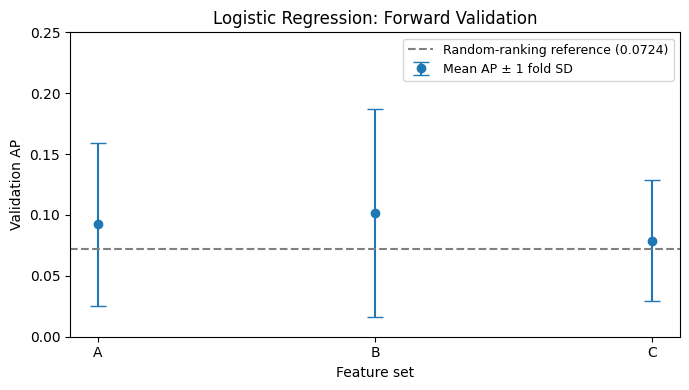

In [66]:
# Average subscription rate in validation blocks
valid_rates = []

for train_data, valid_data in folds:
    valid_rates.append((valid_data["y"] == "yes").mean())

random_ap = np.mean(valid_rates)

# Plot mean AP with fold SD
plt.figure(figsize=(7, 4))

plt.errorbar(
    summary["Feature set"],
    summary["Mean AP"],
    yerr=summary["Fold SD"],
    fmt="o",
    capsize=6,
    label="Mean AP ± 1 fold SD"
)

# Add the random ranking reference
plt.axhline(
    random_ap,
    color="gray",
    linestyle="--",
    label=f"Random-ranking reference ({random_ap:.4f})"
)

plt.xlabel("Feature set")
plt.ylabel("Validation AP")
plt.title("Logistic Regression: Forward Validation")
#plt.ylim(bottom=0)
plt.ylim(0, 0.25)
#plt.legend()
#plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.legend(loc="upper right", fontsize=9)
plt.tight_layout()
# save the figure
plt.savefig("baseline.png", dpi=300)
plt.show()